# 📊 matplotlib Mastery — One Notebook to Rule Them All

A single, hands-on tour of matplotlib from fundamentals to publication-quality figures.
Every section has a **Concept**, a runnable **Demo**, and an **Exercise** with the solution below.

**The one mental model that matters:** a **Figure** is the whole canvas; it contains one
or more **Axes** (a single plot with its own x/y). You draw on an *Axes* object. Prefer the
**object-oriented** style (`fig, ax = plt.subplots()`) over bare `plt.plot()` — it scales to
complex multi-panel figures.

## Table of Contents
1. Setup & anatomy (Figure vs Axes)
2. Line plots
3. Scatter plots
4. Bar charts
5. Histograms & distributions
6. Pie & donut
7. Subplots & layout
8. Labels, legends, limits, ticks
9. Colors, linestyles, markers
10. Annotations & text
11. Styles & themes
12. Twin axes & secondary scales
13. Fill-between & error bars
14. Images, heatmaps & colorbars
15. 3D plotting
16. Saving figures
17. 🏆 Capstone dashboard

## 1. Setup & Anatomy

`%matplotlib inline` renders figures directly in the notebook. `plt.subplots()` returns a
`(figure, axes)` pair — your two handles for everything.

matplotlib 3.11.2


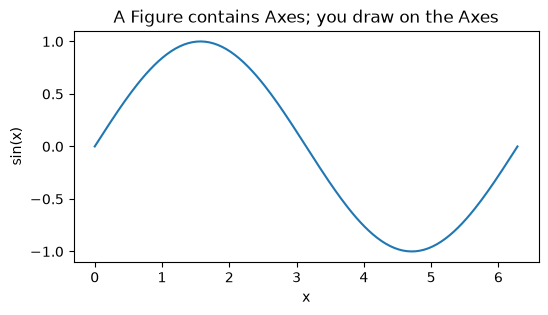

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
print("matplotlib", __import__('matplotlib').__version__)

fig, ax = plt.subplots(figsize=(6, 3))
x = np.linspace(0, 2 * np.pi, 200)
ax.plot(x, np.sin(x))
ax.set_title("A Figure contains Axes; you draw on the Axes")
ax.set_xlabel("x"); ax.set_ylabel("sin(x)")
plt.show()

**Exercise 1** — Create a figure 8×3 inches and plot `cos(x)` over `[0, 4π]` with a title.

In [2]:
# Your turn:

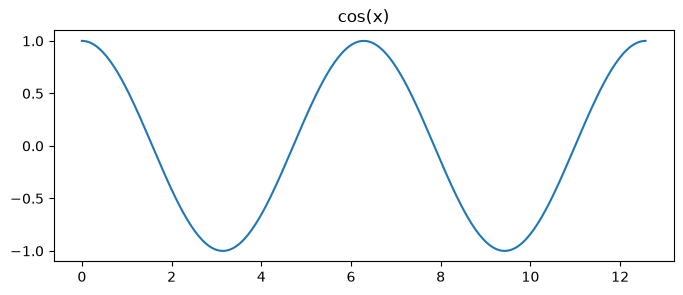

In [3]:
# Solution
fig, ax = plt.subplots(figsize=(8, 3))
x = np.linspace(0, 4 * np.pi, 300)
ax.plot(x, np.cos(x))
ax.set_title("cos(x)")
plt.show()

## 2. Line Plots

The default plot. Multiple lines, labels, and a legend make it informative.

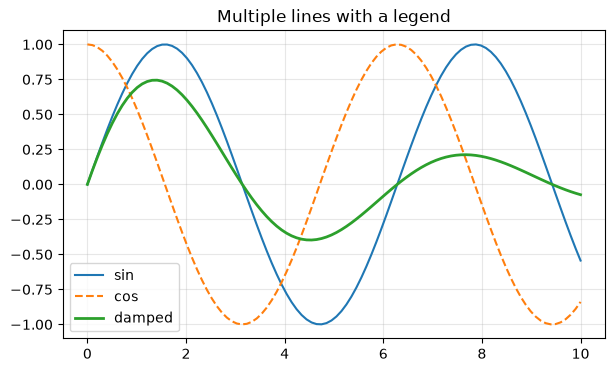

In [4]:
x = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(x), label='sin')
ax.plot(x, np.cos(x), label='cos', linestyle='--')
ax.plot(x, np.sin(x) * np.exp(-x / 5), label='damped', linewidth=2)
ax.set_title("Multiple lines with a legend")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

**Exercise 2** — Plot `y = x`, `y = x²`, `y = x³` for x in [0, 5] on one axes with a legend.

In [5]:
# Your turn:

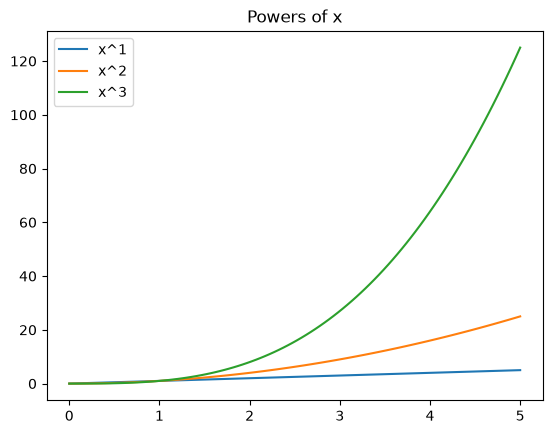

In [6]:
# Solution
x = np.linspace(0, 5, 100)
fig, ax = plt.subplots()
for p in (1, 2, 3):
    ax.plot(x, x ** p, label=f"x^{p}")
ax.legend(); ax.set_title("Powers of x")
plt.show()

## 3. Scatter Plots

Point clouds. Encode extra dimensions via color (`c`) and size (`s`).

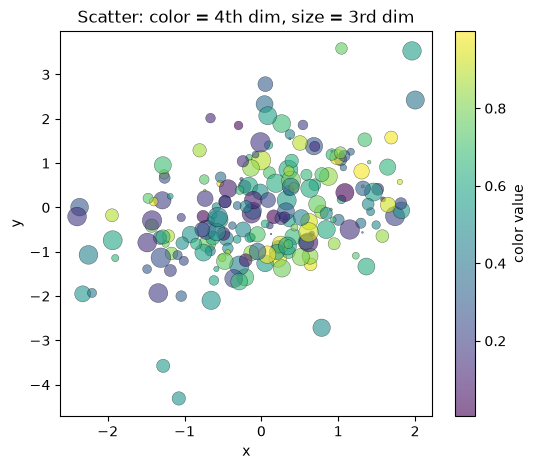

In [7]:
rng = np.random.default_rng(0)
n = 200
x = rng.normal(size=n); y = x * 0.5 + rng.normal(size=n)
colors = rng.random(n); sizes = rng.random(n) * 200

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(x, y, c=colors, s=sizes, alpha=0.6, cmap='viridis', edgecolors='k', linewidths=0.3)
fig.colorbar(sc, ax=ax, label='color value')
ax.set_title("Scatter: color = 4th dim, size = 3rd dim")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

**Exercise 3** — Scatter 100 random points; color each by its distance from the origin.

In [8]:
# Your turn:

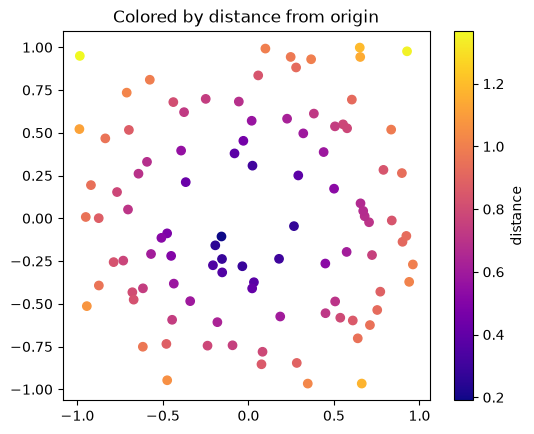

In [9]:
# Solution
rng = np.random.default_rng(1)
x = rng.uniform(-1, 1, 100); y = rng.uniform(-1, 1, 100)
dist = np.hypot(x, y)
fig, ax = plt.subplots()
sc = ax.scatter(x, y, c=dist, cmap='plasma')
fig.colorbar(sc, label='distance')
ax.set_aspect('equal'); ax.set_title("Colored by distance from origin")
plt.show()

## 4. Bar Charts

Compare categories. Vertical (`bar`), horizontal (`barh`), grouped, and stacked.

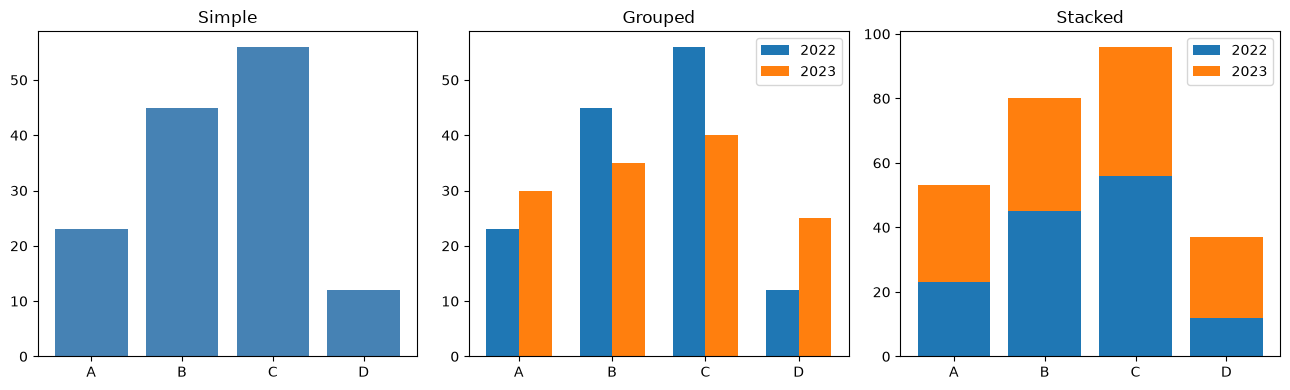

In [10]:
cats = ['A', 'B', 'C', 'D']
v1 = [23, 45, 56, 12]; v2 = [30, 35, 40, 25]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].bar(cats, v1, color='steelblue'); axes[0].set_title("Simple")

x = np.arange(len(cats)); w = 0.35
axes[1].bar(x - w/2, v1, w, label='2022')
axes[1].bar(x + w/2, v2, w, label='2023')
axes[1].set_xticks(x); axes[1].set_xticklabels(cats)
axes[1].legend(); axes[1].set_title("Grouped")

axes[2].bar(cats, v1, label='2022')
axes[2].bar(cats, v2, bottom=v1, label='2023')   # stacked
axes[2].legend(); axes[2].set_title("Stacked")
plt.tight_layout(); plt.show()

**Exercise 4** — Horizontal bar chart of 5 fruits and their counts, sorted so the largest bar is on top.

In [11]:
# Your turn:

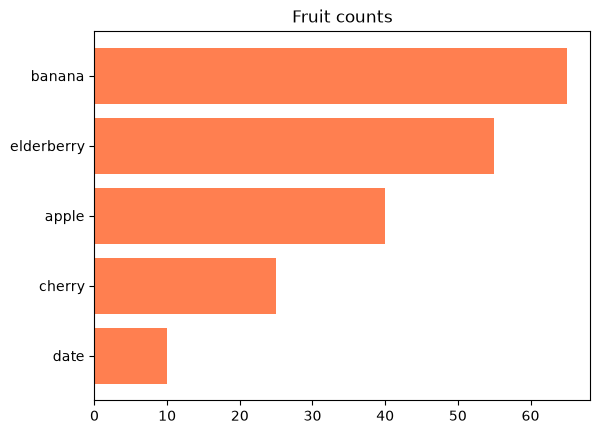

In [12]:
# Solution
fruits = ['apple', 'banana', 'cherry', 'date', 'elderberry']
counts = [40, 65, 25, 10, 55]
order = np.argsort(counts)        # ascending -> largest ends on top in barh
fig, ax = plt.subplots()
ax.barh(np.array(fruits)[order], np.array(counts)[order], color='coral')
ax.set_title("Fruit counts")
plt.show()

## 5. Histograms & Distributions

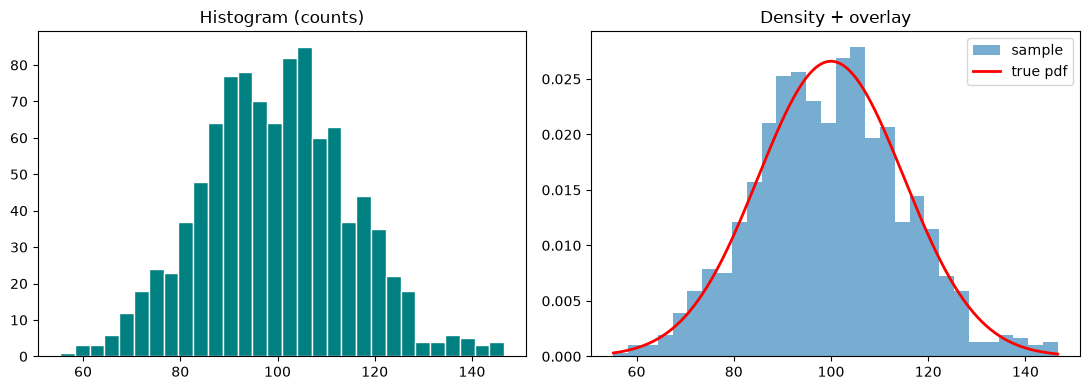

In [13]:
rng = np.random.default_rng(2)
data = rng.normal(100, 15, 1000)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(data, bins=30, color='teal', edgecolor='white')
axes[0].set_title("Histogram (counts)")

axes[1].hist(data, bins=30, density=True, alpha=0.6, label='sample')
xs = np.linspace(data.min(), data.max(), 200)
pdf = np.exp(-(xs - 100)**2 / (2 * 15**2)) / (15 * np.sqrt(2 * np.pi))
axes[1].plot(xs, pdf, 'r-', lw=2, label='true pdf')
axes[1].legend(); axes[1].set_title("Density + overlay")
plt.tight_layout(); plt.show()

**Exercise 5** — Overlay two histograms (two different normal samples) on one axes with transparency and a legend.

In [14]:
# Your turn:

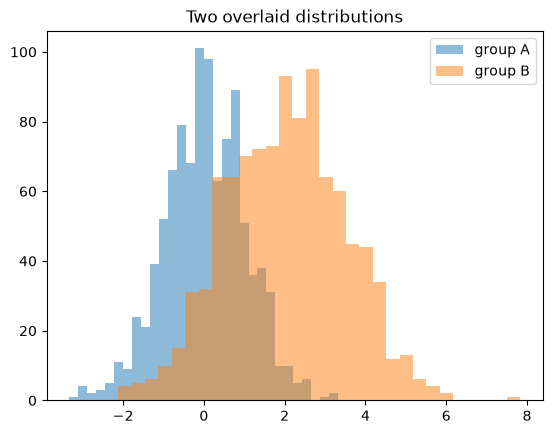

In [15]:
# Solution
rng = np.random.default_rng(3)
a = rng.normal(0, 1, 1000); b = rng.normal(2, 1.5, 1000)
fig, ax = plt.subplots()
ax.hist(a, bins=30, alpha=0.5, label='group A')
ax.hist(b, bins=30, alpha=0.5, label='group B')
ax.legend(); ax.set_title("Two overlaid distributions")
plt.show()

## 6. Pie & Donut

Use sparingly — bars usually compare better. Good for a few parts of a whole.

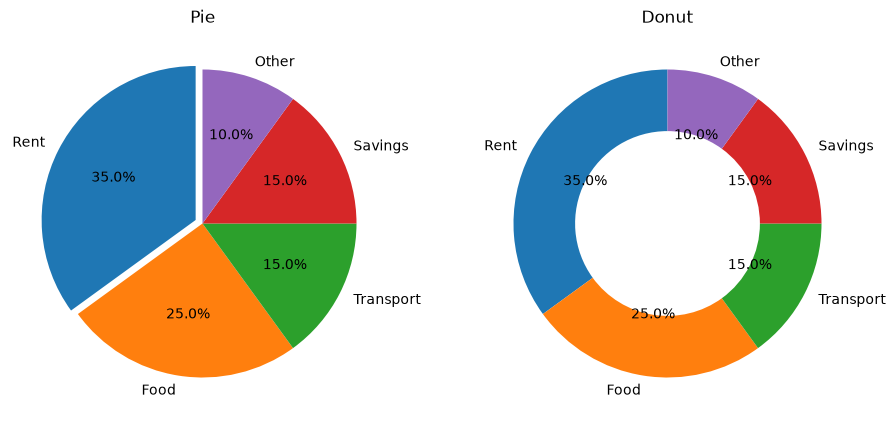

In [16]:
labels = ['Rent', 'Food', 'Transport', 'Savings', 'Other']
sizes = [35, 25, 15, 15, 10]
explode = [0.05, 0, 0, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].pie(sizes, labels=labels, autopct='%1.1f%%', explode=explode, startangle=90)
axes[0].set_title("Pie")

axes[1].pie(sizes, labels=labels, autopct='%1.1f%%',
            wedgeprops=dict(width=0.4), startangle=90)   # donut
axes[1].set_title("Donut")
plt.show()

**Exercise 6** — Make a donut chart of time spent in a day across Sleep/Work/Leisure/Chores.

In [17]:
# Your turn:

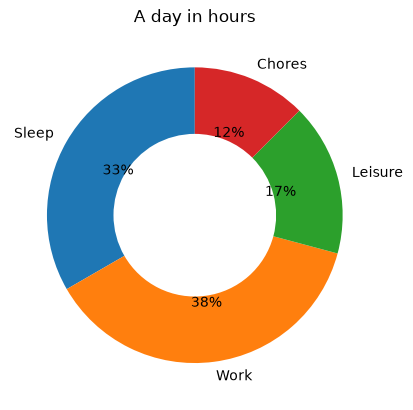

In [18]:
# Solution
fig, ax = plt.subplots()
ax.pie([8, 9, 4, 3], labels=['Sleep', 'Work', 'Leisure', 'Chores'],
       autopct='%1.0f%%', wedgeprops=dict(width=0.45), startangle=90)
ax.set_title("A day in hours")
plt.show()

## 7. Subplots & Layout

`plt.subplots(nrows, ncols)` returns a grid of Axes. `tight_layout` / `constrained_layout`
prevents overlap; `GridSpec` builds uneven grids.

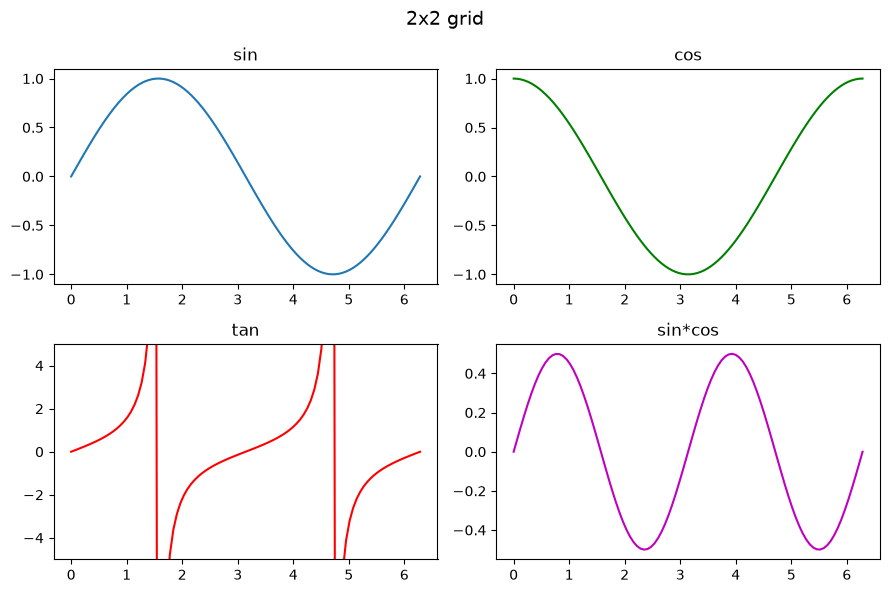

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
x = np.linspace(0, 2 * np.pi, 100)
axes[0, 0].plot(x, np.sin(x)); axes[0, 0].set_title("sin")
axes[0, 1].plot(x, np.cos(x), 'g'); axes[0, 1].set_title("cos")
axes[1, 0].plot(x, np.tan(x), 'r'); axes[1, 0].set_ylim(-5, 5); axes[1, 0].set_title("tan")
axes[1, 1].plot(x, np.sin(x) * np.cos(x), 'm'); axes[1, 1].set_title("sin*cos")
fig.suptitle("2x2 grid", fontsize=14)
plt.tight_layout(); plt.show()

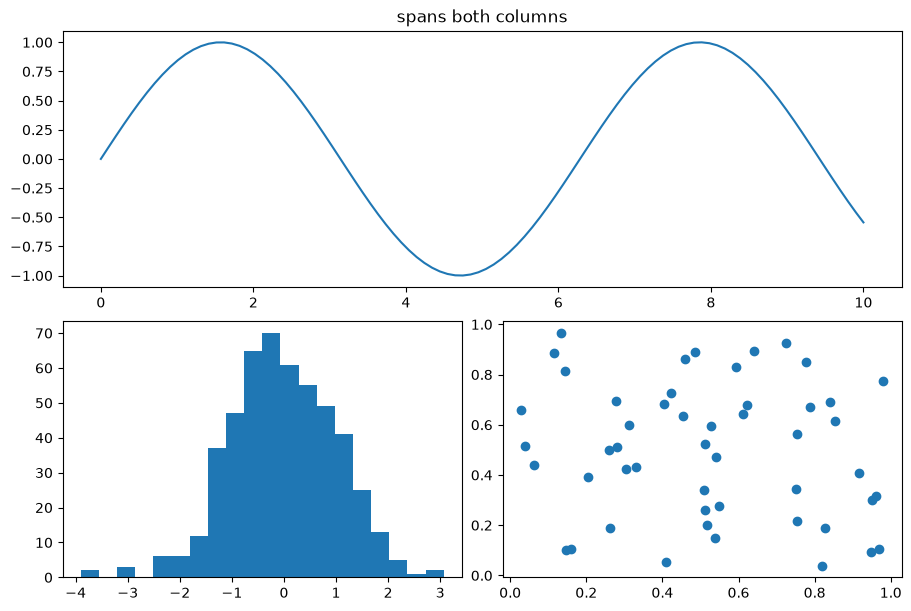

In [20]:
# Uneven layout with GridSpec: one wide plot on top, two below
fig = plt.figure(figsize=(9, 6), constrained_layout=True)
gs = fig.add_gridspec(2, 2)
ax_top = fig.add_subplot(gs[0, :])
ax_bl = fig.add_subplot(gs[1, 0])
ax_br = fig.add_subplot(gs[1, 1])
x = np.linspace(0, 10, 100)
ax_top.plot(x, np.sin(x)); ax_top.set_title("spans both columns")
ax_bl.hist(np.random.default_rng(0).normal(size=500), bins=20)
ax_br.scatter(np.random.default_rng(1).random(50), np.random.default_rng(2).random(50))
plt.show()

**Exercise 7** — Create a 1×3 row of subplots sharing the y-axis, each showing a different power of x.

In [21]:
# Your turn:

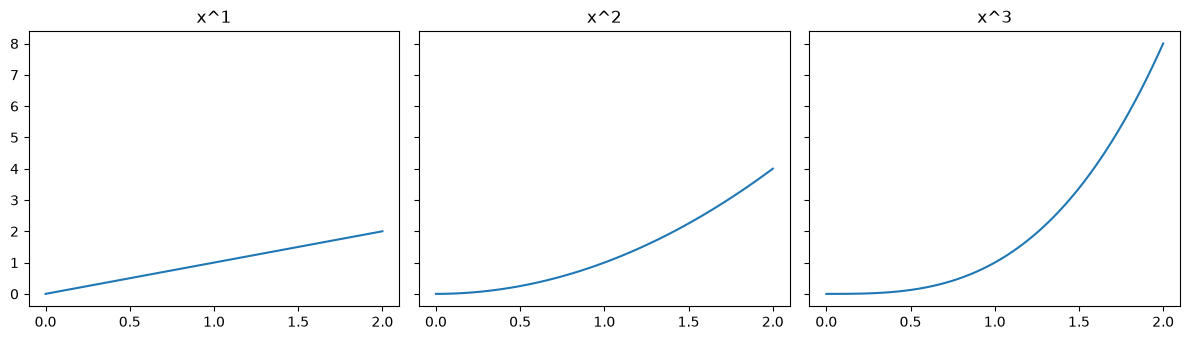

In [22]:
# Solution
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
x = np.linspace(0, 2, 100)
for ax, p in zip(axes, (1, 2, 3)):
    ax.plot(x, x ** p); ax.set_title(f"x^{p}")
plt.tight_layout(); plt.show()

## 8. Labels, Legends, Limits, Ticks

The grammar of a readable chart: title, axis labels, legend, sensible limits and tick marks.

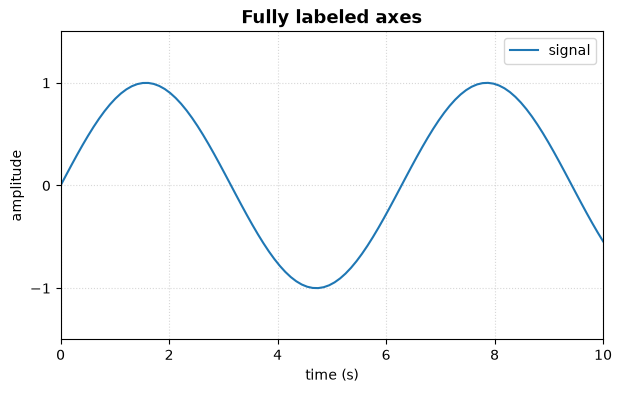

In [23]:
x = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(x), label='signal')
ax.set_title("Fully labeled axes", fontsize=13, fontweight='bold')
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
ax.set_xlim(0, 10); ax.set_ylim(-1.5, 1.5)
ax.set_xticks(np.arange(0, 11, 2))
ax.set_yticks([-1, 0, 1])
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.5)
plt.show()

**Exercise 8** — Plot sin(x) over [0, 2π] with x-ticks labeled `0, π/2, π, 3π/2, 2π`.

In [24]:
# Your turn:

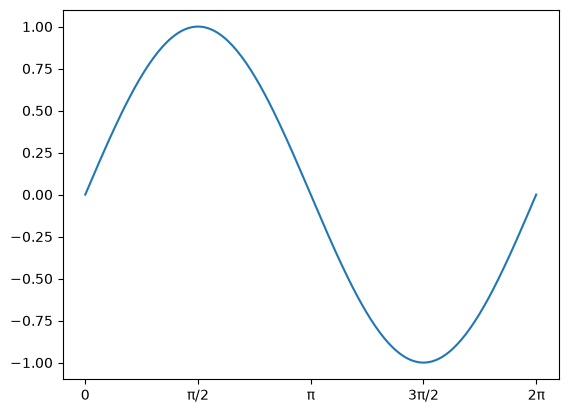

In [25]:
# Solution
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
plt.show()

## 9. Colors, Linestyles, Markers

Control appearance with `color` (names, hex, RGB), `linestyle`, `marker`, `linewidth`, `alpha`.

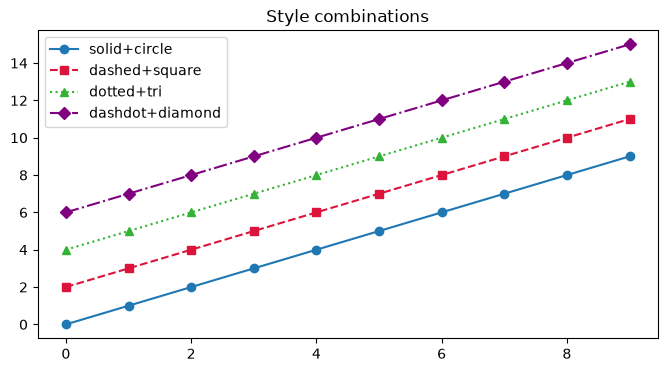

In [26]:
x = np.arange(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, x, color='#1f77b4', linestyle='-', marker='o', label='solid+circle')
ax.plot(x, x + 2, color='crimson', linestyle='--', marker='s', label='dashed+square')
ax.plot(x, x + 4, color=(0.2, 0.7, 0.2), linestyle=':', marker='^', label='dotted+tri')
ax.plot(x, x + 6, color='purple', linestyle='-.', marker='D', label='dashdot+diamond')
ax.legend(); ax.set_title("Style combinations")
plt.show()

**Exercise 9** — Plot a dashed orange line with star markers at each point for `y = x² mod 7` over x in 0..9.

In [27]:
# Your turn:

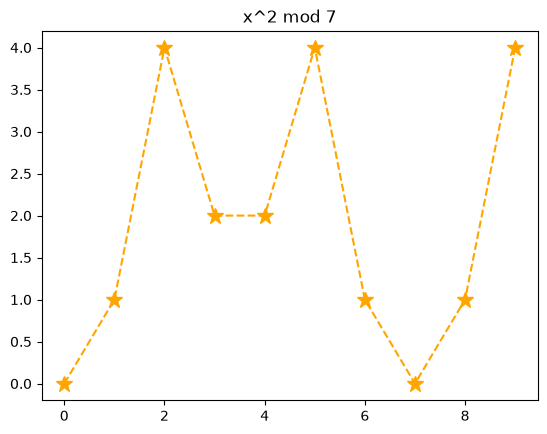

In [28]:
# Solution
x = np.arange(10)
fig, ax = plt.subplots()
ax.plot(x, (x ** 2) % 7, color='orange', linestyle='--', marker='*', markersize=12)
ax.set_title("x^2 mod 7")
plt.show()

## 10. Annotations & Text

Point out features with `annotate` (arrow + label) and free `text`.

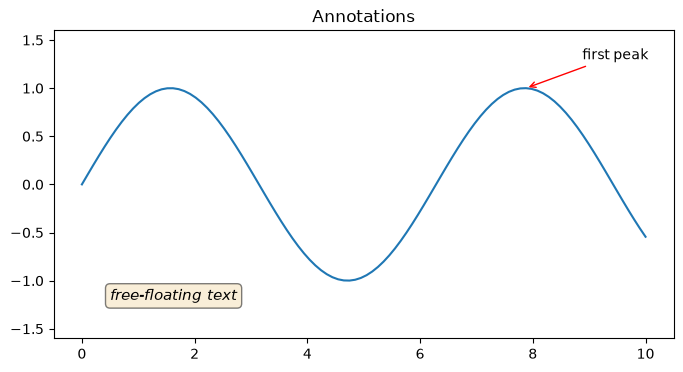

In [29]:
x = np.linspace(0, 10, 100)
y = np.sin(x)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)
peak = x[np.argmax(y)]
ax.annotate('first peak', xy=(peak, 1), xytext=(peak + 1, 1.3),
            arrowprops=dict(arrowstyle='->', color='red'))
ax.text(0.5, -1.2, "free-floating text", fontsize=11, style='italic',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.set_ylim(-1.6, 1.6); ax.set_title("Annotations")
plt.show()

**Exercise 10** — Plot a parabola `y=x²-4x+3` over [0,4] and annotate its minimum with an arrow.

In [30]:
# Your turn:

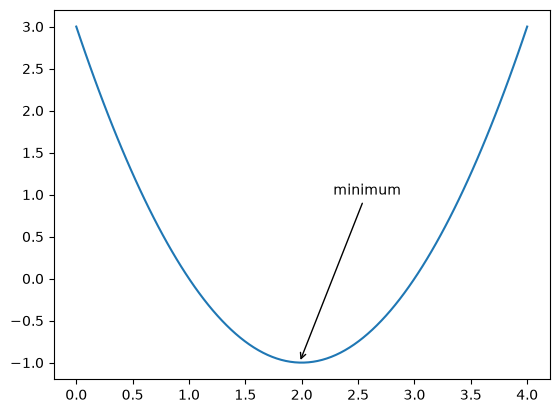

In [31]:
# Solution
x = np.linspace(0, 4, 100)
y = x**2 - 4*x + 3
fig, ax = plt.subplots()
ax.plot(x, y)
xmin = x[np.argmin(y)]; ymin = y.min()
ax.annotate('minimum', xy=(xmin, ymin), xytext=(xmin + 0.3, ymin + 2),
            arrowprops=dict(arrowstyle='->'))
plt.show()

## 11. Styles & Themes

`plt.style` swaps the whole look at once. Use a context manager to apply a style locally.

['bmh', 'classic', 'dark_background', 'fivethirtyeight', 'ggplot', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind']


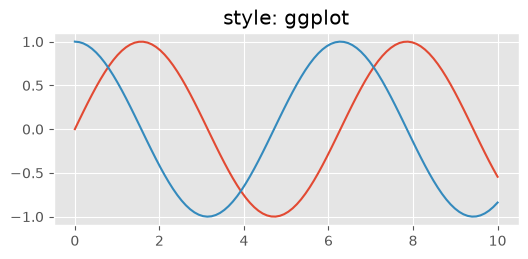

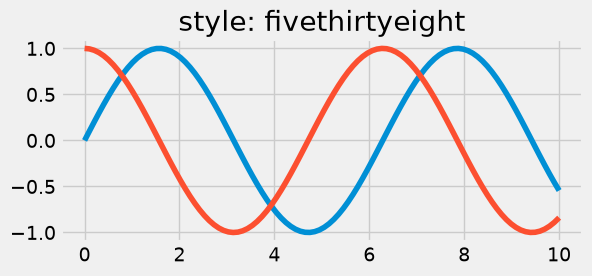

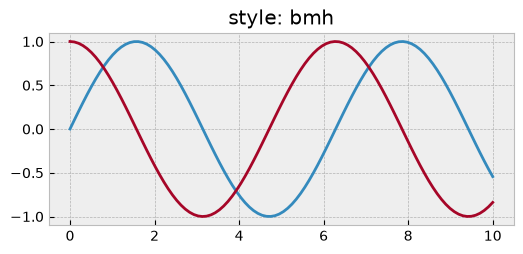

In [32]:
print([s for s in plt.style.available if 'seaborn' in s or s in
       ('ggplot', 'bmh', 'fivethirtyeight', 'dark_background', 'classic')][:8])

x = np.linspace(0, 10, 100)
for style in ['ggplot', 'fivethirtyeight', 'bmh']:
    with plt.style.context(style):
        fig, ax = plt.subplots(figsize=(6, 2.5))
        ax.plot(x, np.sin(x)); ax.plot(x, np.cos(x))
        ax.set_title(f"style: {style}")
        plt.show()

**Exercise 11** — Render the same scatter plot under the `'dark_background'` style using a `with` block.

In [33]:
# Your turn:

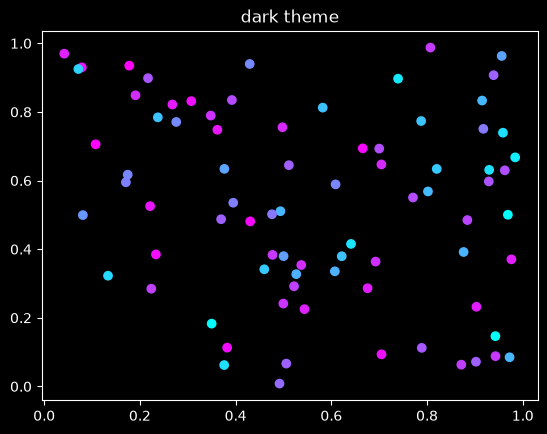

In [34]:
# Solution
rng = np.random.default_rng(4)
with plt.style.context('dark_background'):
    fig, ax = plt.subplots()
    ax.scatter(rng.random(80), rng.random(80), c=rng.random(80), cmap='cool')
    ax.set_title("dark theme")
    plt.show()

## 12. Twin Axes & Secondary Scales

`ax.twinx()` overlays a second y-axis sharing the same x — for two series with different units.

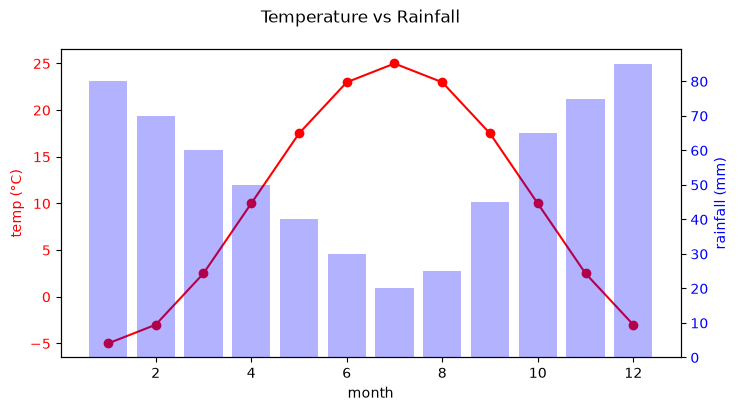

In [35]:
months = np.arange(1, 13)
temp = 10 + 15 * np.sin((months - 4) / 12 * 2 * np.pi)
rain = np.array([80, 70, 60, 50, 40, 30, 20, 25, 45, 65, 75, 85])

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(months, temp, 'r-o', label='temp')
ax1.set_xlabel("month"); ax1.set_ylabel("temp (°C)", color='red')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.bar(months, rain, alpha=0.3, color='blue', label='rain')
ax2.set_ylabel("rainfall (mm)", color='blue')
ax2.tick_params(axis='y', labelcolor='blue')
fig.suptitle("Temperature vs Rainfall")
plt.show()

**Exercise 12** — Plot a company's revenue (line) and employee count (bars) over 5 years on twin y-axes.

In [36]:
# Your turn:

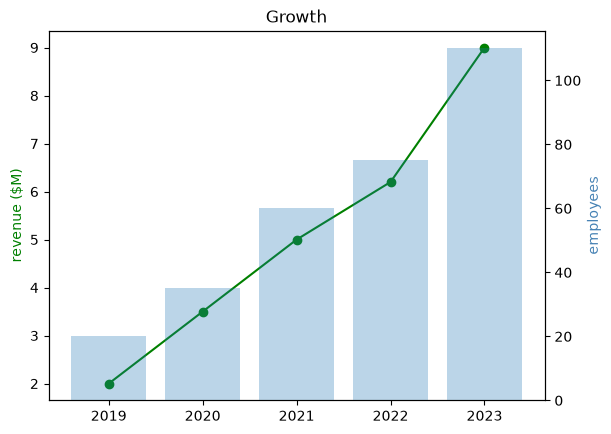

In [37]:
# Solution
years = np.arange(2019, 2024)
revenue = [2, 3.5, 5, 6.2, 9]
employees = [20, 35, 60, 75, 110]
fig, ax1 = plt.subplots()
ax1.plot(years, revenue, 'g-o'); ax1.set_ylabel("revenue ($M)", color='green')
ax2 = ax1.twinx()
ax2.bar(years, employees, alpha=0.3); ax2.set_ylabel("employees", color='steelblue')
plt.title("Growth"); plt.show()

## 13. Fill-Between & Error Bars

Show ranges and uncertainty: `fill_between` for bands, `errorbar` for measurement error.

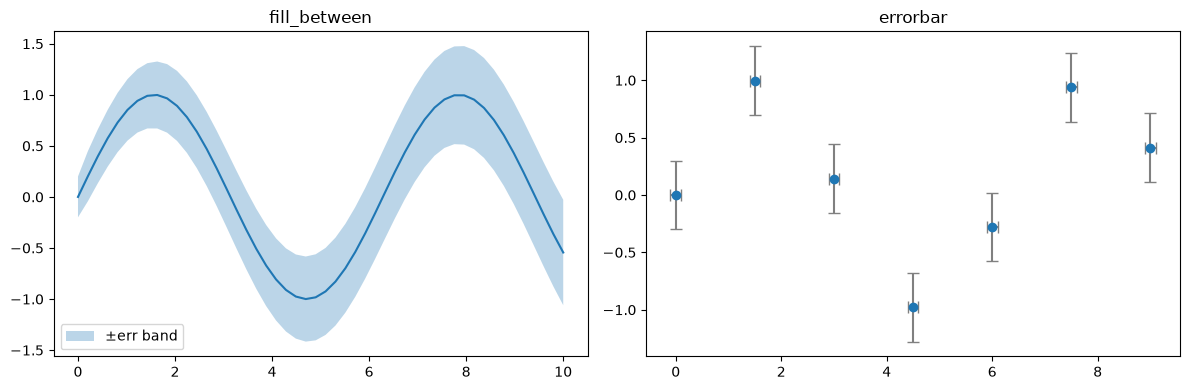

In [38]:
x = np.linspace(0, 10, 50)
y = np.sin(x)
err = 0.2 + 0.1 * np.sqrt(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, y)
axes[0].fill_between(x, y - err, y + err, alpha=0.3, label='±err band')
axes[0].legend(); axes[0].set_title("fill_between")

xs = np.arange(0, 10, 1.5)
ys = np.sin(xs)
axes[1].errorbar(xs, ys, yerr=0.3, xerr=0.1, fmt='o', capsize=4, ecolor='gray')
axes[1].set_title("errorbar")
plt.tight_layout(); plt.show()

**Exercise 13** — Plot a mean curve `cos(x)` with a shaded ±0.3 confidence band over [0, 2π].

In [39]:
# Your turn:

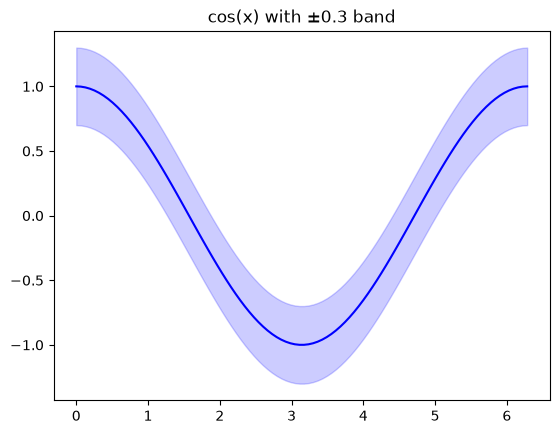

In [40]:
# Solution
x = np.linspace(0, 2 * np.pi, 100)
y = np.cos(x)
fig, ax = plt.subplots()
ax.plot(x, y, 'b-')
ax.fill_between(x, y - 0.3, y + 0.3, color='blue', alpha=0.2)
ax.set_title("cos(x) with ±0.3 band")
plt.show()

## 14. Images, Heatmaps & Colorbars

`imshow` renders a 2-D array as an image/heatmap. Always add a `colorbar` to decode values.

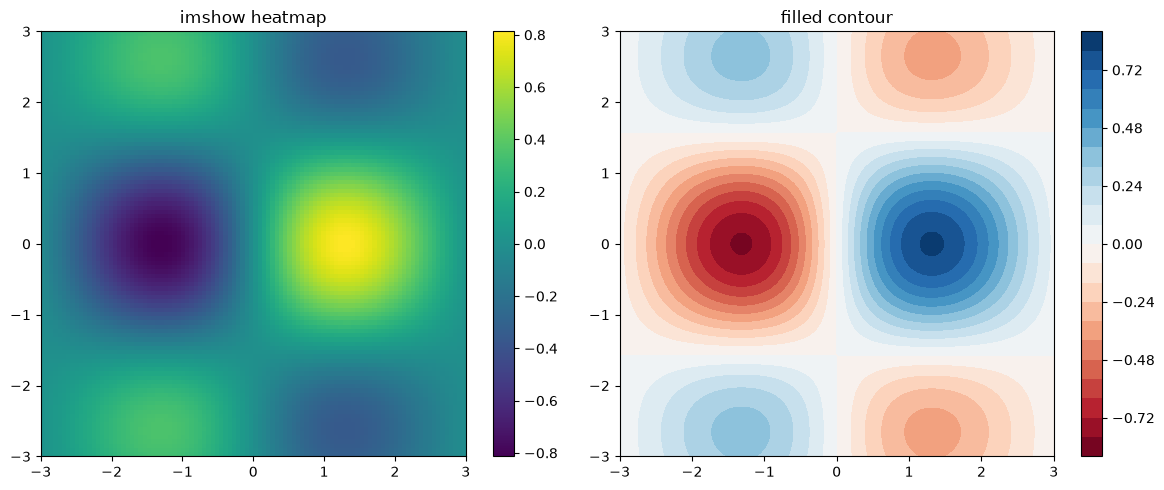

In [41]:
# A 2-D function as a heatmap
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
Z = np.sin(X) * np.cos(Y) * np.exp(-(X**2 + Y**2) / 10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(Z, cmap='viridis', extent=[-3, 3, -3, 3], origin='lower')
fig.colorbar(im0, ax=axes[0]); axes[0].set_title("imshow heatmap")

cs = axes[1].contourf(X, Y, Z, levels=20, cmap='RdBu')
fig.colorbar(cs, ax=axes[1]); axes[1].set_title("filled contour")
plt.tight_layout(); plt.show()

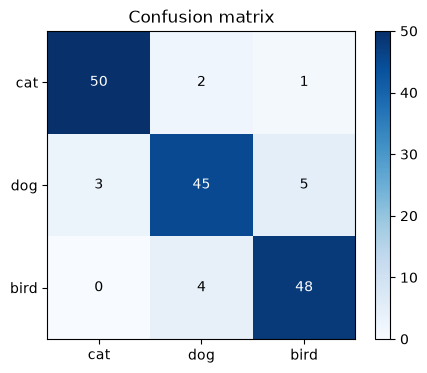

In [42]:
# A labeled confusion-matrix-style heatmap
mat = np.array([[50, 2, 1], [3, 45, 5], [0, 4, 48]])
labels = ['cat', 'dog', 'bird']
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(mat, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(labels)
ax.set_yticks(range(3)); ax.set_yticklabels(labels)
for i in range(3):
    for j in range(3):
        ax.text(j, i, mat[i, j], ha='center', va='center',
                color='white' if mat[i, j] > 25 else 'black')
ax.set_title("Confusion matrix"); fig.colorbar(im)
plt.show()

**Exercise 14** — Render a 10×10 random matrix as a heatmap with the `'magma'` colormap and a colorbar.

In [43]:
# Your turn:

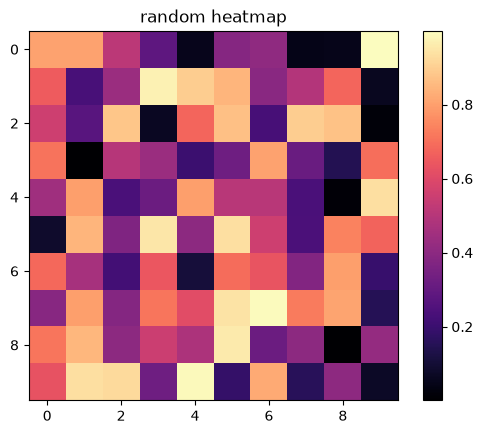

In [44]:
# Solution
rng = np.random.default_rng(5)
M = rng.random((10, 10))
fig, ax = plt.subplots()
im = ax.imshow(M, cmap='magma')
fig.colorbar(im); ax.set_title("random heatmap")
plt.show()

## 15. 3D Plotting

Add `projection='3d'` to get an Axes3D for surfaces, wireframes, and 3-D scatter.

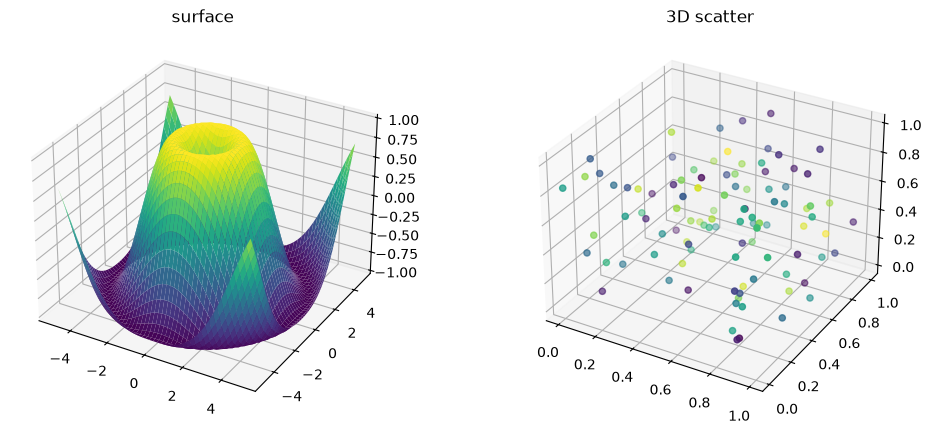

In [45]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: enables 3d projection

x = np.linspace(-5, 5, 50); y = np.linspace(-5, 5, 50)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis')
ax1.set_title("surface")

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
rng = np.random.default_rng(6)
ax2.scatter(rng.random(100), rng.random(100), rng.random(100), c=rng.random(100))
ax2.set_title("3D scatter")
plt.show()

**Exercise 15** — Plot the 3-D surface of `Z = X² + Y²` (a paraboloid) over [-3, 3]².

In [46]:
# Your turn:

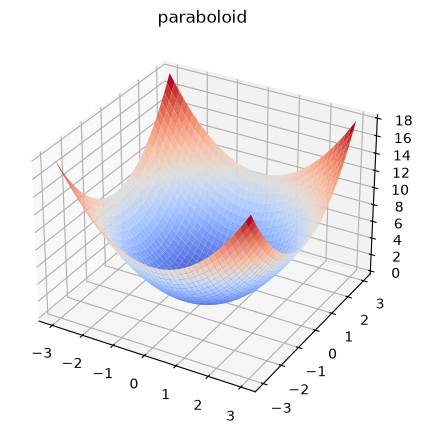

In [47]:
# Solution
x = np.linspace(-3, 3, 40); y = np.linspace(-3, 3, 40)
X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, Y, Z, cmap='coolwarm')
ax.set_title("paraboloid")
plt.show()

## 16. Saving Figures

`fig.savefig(path, dpi=..., bbox_inches='tight')`. Choose format by extension (PNG, SVG, PDF).

In [48]:
import tempfile, os
tmp = tempfile.mkdtemp()

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.linspace(0, 10, 100), np.sin(np.linspace(0, 10, 100)))
ax.set_title("Saved figure")

for ext in ['png', 'svg', 'pdf']:
    path = os.path.join(tmp, f"plot.{ext}")
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"{ext}: {os.path.getsize(path):,} bytes -> {path}")
plt.close(fig)   # free memory when saving many figures
print("done")

png: 29,366 bytes -> /var/folders/qy/zpcqqyj54q36r_2_vkk5d6gw0000gn/T/tmpms6wp5v6/plot.png
svg: 19,287 bytes -> /var/folders/qy/zpcqqyj54q36r_2_vkk5d6gw0000gn/T/tmpms6wp5v6/plot.svg


pdf: 11,466 bytes -> /var/folders/qy/zpcqqyj54q36r_2_vkk5d6gw0000gn/T/tmpms6wp5v6/plot.pdf
done


**Exercise 16** — Save a bar chart to a PNG at 200 dpi with a tight bounding box, and print the file size.

In [49]:
# Your turn:

In [50]:
# Solution
import tempfile, os
tmp = tempfile.mkdtemp()
fig, ax = plt.subplots()
ax.bar(['a', 'b', 'c'], [3, 7, 5])
path = os.path.join(tmp, "bars.png")
fig.savefig(path, dpi=200, bbox_inches='tight')
print(os.path.getsize(path), "bytes")
plt.close(fig)

12516 bytes


## 17. 🏆 Capstone — Build a Dashboard

Combine layout, multiple chart types, styling, and annotations into one figure.

**Capstone — Sales dashboard.** In a single figure with a 2×2 grid, show: (1) a monthly revenue line with the peak annotated, (2) revenue by region as a bar chart, (3) a histogram of order values, (4) a scatter of order value vs. quantity colored by region code. Give the figure a super-title.

In [51]:
# Your turn:

/var/folders/qy/zpcqqyj54q36r_2_vkk5d6gw0000gn/T/ipykernel_79498/1300814597.py:42: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/I590236/anaconda3/envs/k_tab/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


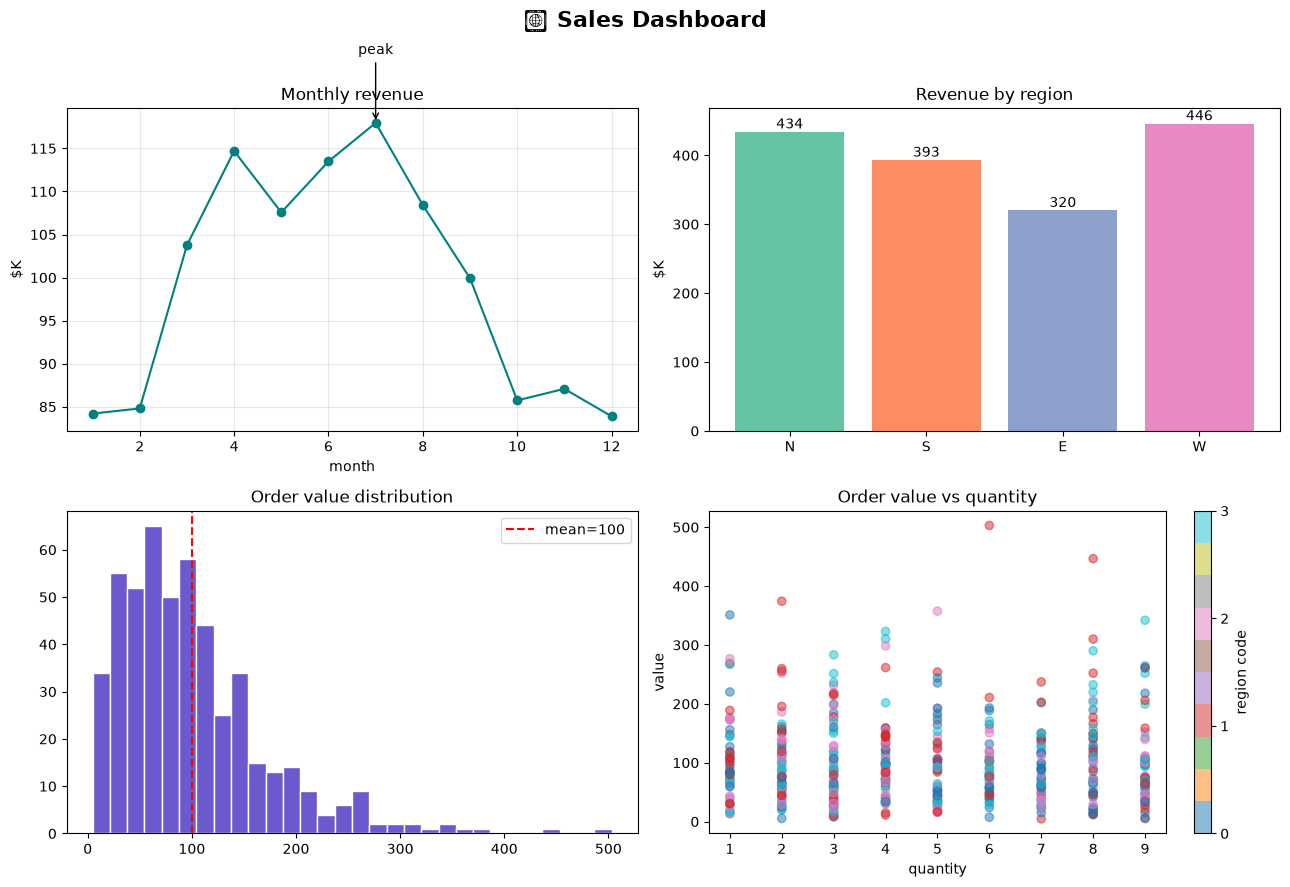

In [52]:
# Solution
rng = np.random.default_rng(42)
months = np.arange(1, 13)
revenue = 100 + 20 * np.sin((months - 3) / 12 * 2 * np.pi) + rng.normal(0, 5, 12)
regions = ['N', 'S', 'E', 'W']
region_rev = rng.integers(200, 500, 4)
order_values = rng.gamma(2, 50, 500)
qty = rng.integers(1, 10, 500)
region_code = rng.integers(0, 4, 500)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (1) revenue line + peak annotation
ax = axes[0, 0]
ax.plot(months, revenue, 'o-', color='teal')
pk = months[np.argmax(revenue)]
ax.annotate('peak', xy=(pk, revenue.max()), xytext=(pk, revenue.max() + 8),
            arrowprops=dict(arrowstyle='->'), ha='center')
ax.set_title("Monthly revenue"); ax.set_xlabel("month"); ax.set_ylabel("$K")
ax.grid(alpha=0.3)

# (2) revenue by region
ax = axes[0, 1]
bars = ax.bar(regions, region_rev, color=plt.cm.Set2(range(4)))
ax.set_title("Revenue by region"); ax.set_ylabel("$K")
for b, v in zip(bars, region_rev):
    ax.text(b.get_x() + b.get_width()/2, v + 5, str(v), ha='center')

# (3) histogram of order values
ax = axes[1, 0]
ax.hist(order_values, bins=30, color='slateblue', edgecolor='white')
ax.axvline(order_values.mean(), color='red', linestyle='--', label=f"mean={order_values.mean():.0f}")
ax.set_title("Order value distribution"); ax.legend()

# (4) scatter value vs qty
ax = axes[1, 1]
sc = ax.scatter(qty, order_values, c=region_code, cmap='tab10', alpha=0.5)
ax.set_title("Order value vs quantity"); ax.set_xlabel("quantity"); ax.set_ylabel("value")
fig.colorbar(sc, ax=ax, label='region code', ticks=range(4))

fig.suptitle("📈 Sales Dashboard", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🎓 Next Steps
- Learn the OO API reflexively: `fig, ax = plt.subplots()` then method calls on `ax`.
- Set figure defaults globally via `plt.rcParams`.
- Move to **seaborn** (next notebook) for statistical charts with far less code.